## __New York City Taxi Trip Duration__

Kaggle is challenging you to build a model that predicts the total ride duration of taxi trips in New York City.

__Data fields__  
_id_ - a unique identifier for each trip  
_vendor_id_ - a code indicating the provider associated with the trip record  
_pickup_datetime_ - date and time when the meter was engaged  
_dropoff_datetime_ - date and time when the meter was disengaged  
_passenger_count_ - the number of passengers in the vehicle (driver entered value)  
_pickup_longitude_ - the longitude where the meter was engaged   
_pickup_latitude_ - the latitude where the meter was engaged   
_dropoff_longitude_ - the longitude where the meter was disengaged  
_dropoff_latitude_ - the latitude where the meter was disengaged  
_store_and_fwd_flag_ - This flag indicates whether the trip record was held in vehicle memory before sending to the vendor because the vehicle did not have a connection to the server - Y=store and forward; N=not a store and forward trip   
_trip_duration_ - duration of the trip in seconds

- ___Imports___

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from geopy.distance import geodesic
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from keras import Sequential
from keras.layers import Dense, Input, BatchNormalization, Dropout
from keras.optimizers import RMSprop
from keras.callbacks import EarlyStopping
from keras.metrics import R2Score
from geopy.distance import geodesic
from keras.regularizers import l1_l2
from sklearn.metrics import root_mean_squared_log_error, root_mean_squared_error, r2_score

- ___Read the data___

In [2]:
data = pd.read_csv("data/train.csv")
data.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


- ___Check Null or Duplicated instances___ 

No null or duplicated instances

In [3]:
data.isnull().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [4]:
data.duplicated().sum()

np.int64(0)

- ___Get Info___

We have `id`, `pickup_datetime`, `dropoff_datetime`, `store_and_fwd_flag` as Strings.  
Maybe we can drop "id" and "vendor_id"

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 122.4 MB


In [6]:
data.describe().round(2)

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1458644.00,1458644.00,1458644.00,1458644.00,1458644.00,1458644.00,1458644.00
mean,1.53,1.66,-73.97,40.75,-73.97,40.75,959.49
std,0.50,1.31,0.07,0.03,0.07,0.04,5237.43
min,1.00,0.00,-121.93,34.36,-121.93,32.18,1.00
25%,1.00,1.00,-73.99,40.74,-73.99,40.74,397.00
50%,2.00,1.00,-73.98,40.75,-73.98,40.75,662.00
75%,2.00,2.00,-73.97,40.77,-73.96,40.77,1075.00
max,2.00,9.00,-61.34,51.88,-61.34,43.92,3526282.00


- ___Categorise the features___

Quantitative: ['passenger_count', 'pickup_longitude','pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']  
Qualitative: ['vendor_id', 'store_and_fwd_flag']

- ___Drop "Id" features___
- Also  `dropoff_datetime` since its not present in test data
- Also `store_and_fwd_flag` since its of no use in prediction

In [7]:
data.drop(['id', 'dropoff_datetime', 'store_and_fwd_flag'], axis=1, inplace=True)

### Univariate Analysis

- ___vendor_id___  
53% rides with vendor 2  
47% rides with vendor 1  

Rides with vendor 1 have less avg trip duration than with vendor 2

In [8]:
data['vendor_id'].value_counts()/len(data) * 100

vendor_id
2    53.495027
1    46.504973
Name: count, dtype: float64

In [16]:
data.groupby(['vendor_id'])['trip_duration'].mean()

vendor_id
1     845.438244
2    1058.643164
Name: trip_duration, dtype: float64

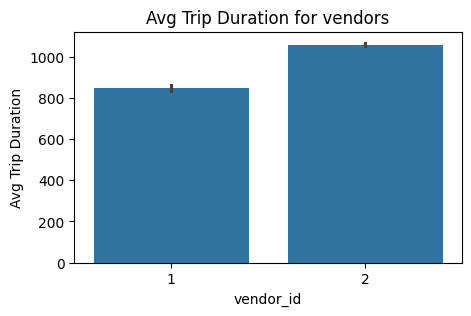

In [24]:
plt.figure(figsize=(5,3))
sns.barplot(x=data['vendor_id'], y=data['trip_duration'])
plt.title("Avg Trip Duration for vendors")
plt.ylabel("Avg Trip Duration")
plt.show()

- ___pickup_datetime___   
All the instances are from 2016 data only.

In [20]:
len(data['pickup_datetime']) == data['pickup_datetime'].str.contains("2016").sum()

np.True_

- ___passenger_count___   
70% of rides contain a single passenger, followed by 14% for two passengers, and 4% for three passengers

There are also rides with 0,7,8,9 but only one or two of them are present

In [21]:
data['passenger_count'].value_counts().sort_index()

passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64

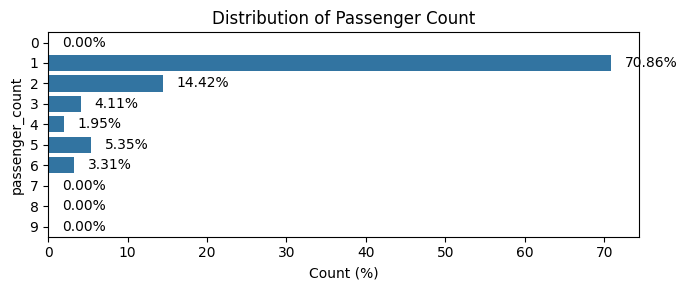

In [33]:
distribution = data['passenger_count'].value_counts() / len(data) * 100
fig, ax = plt.subplots(figsize=(7, 3))
sns.barplot(x=distribution.values, y=distribution.index, ax=ax, orient='h')
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=10)
ax.set_xlabel("Count (%)")
ax.set_title("Distribution of Passenger Count")

plt.tight_layout()
plt.show()

<Axes: xlabel='passenger_count', ylabel='trip_duration'>

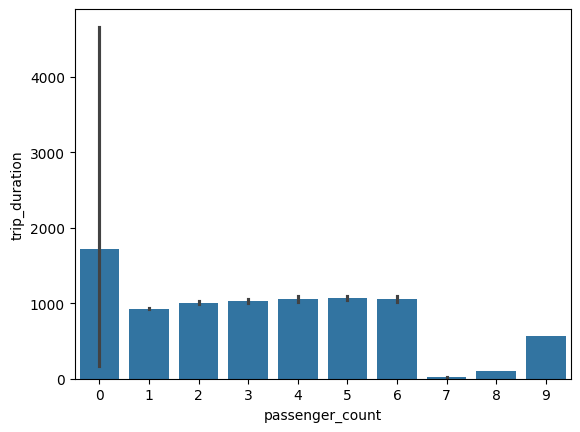

In [34]:
sns.barplot(x=data['passenger_count'], y=data['trip_duration'])

- __pickup_longitude, pickup_latitude, dropoff_longitude, dropoff_latitude___    
Check the range of longitude and latitudes

In [35]:
data.describe()[['pickup_longitude', 'pickup_latitude', 'dropoff_longitude','dropoff_latitude']].astype(int)

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
count,1458644,1458644,1458644,1458644
mean,-73,40,-73,40
std,0,0,0,0
min,-121,34,-121,32
25%,-73,40,-73,40
50%,-73,40,-73,40
75%,-73,40,-73,40
max,-61,51,-61,43


- ___Trip Duration___    
5% of the instances are outliers - thats approx 75k instances   
few instances go way too high in value 

_Lets remove all the outliers for now and train the model, if we see bad performance then we will add some outliers back into the data_

In [37]:
data.describe()['trip_duration'].astype(int)

count    1458644
mean         959
std         5237
min            1
25%          397
50%          662
75%         1075
max      3526282
Name: trip_duration, dtype: int64

<Axes: ylabel='trip_duration'>

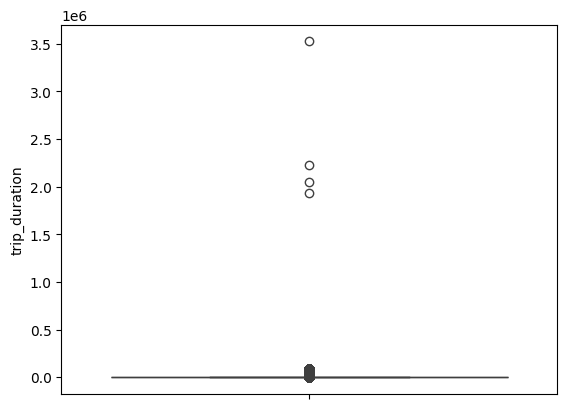

In [38]:
sns.boxplot(data['trip_duration'])

In [39]:
##Get outliers
Q1 = data['trip_duration'].quantile(0.25)
Q2 = data['trip_duration'].quantile(0.75)

IQR = Q2 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q2 + 1.5*IQR

print("lower_bound: ", lower_bound)
print("upper_bound: ", upper_bound)

lower_bound:  -620.0
upper_bound:  2092.0


In [40]:
## Percentage outliers
len(data[data['trip_duration']>upper_bound])/len(data) * 100

5.088287477958981

<Axes: xlabel='trip_duration', ylabel='Density'>

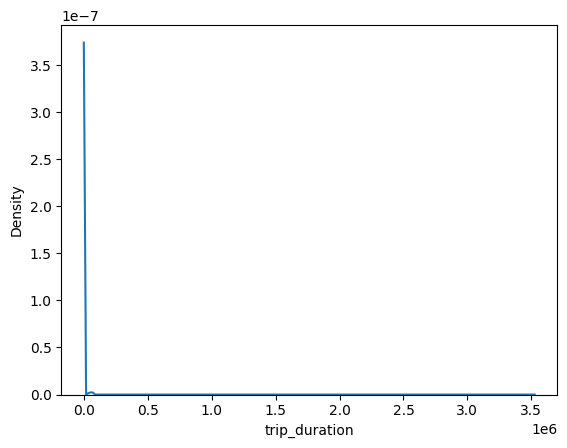

In [41]:
sns.kdeplot(data['trip_duration'])

<Axes: xlabel='trip_duration', ylabel='Density'>

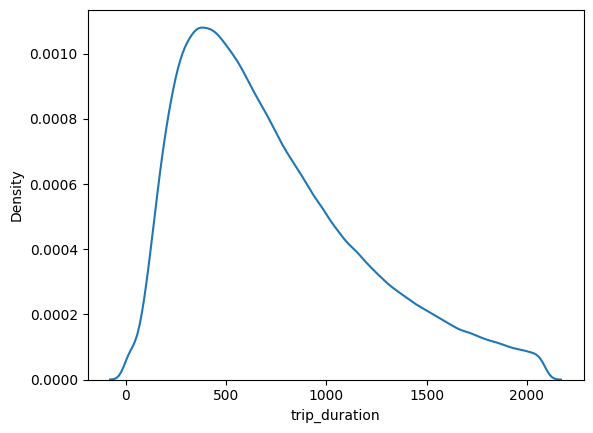

In [42]:
sns.kdeplot(data[data['trip_duration']<upper_bound]['trip_duration'])

_This confirms that the data is highly right skewed_

In [44]:
## Check the 10 largest in hours
data['trip_duration'].nlargest(10) / (60*60)

978383     979.522778
924150     618.781111
680594     569.327222
355003     538.815556
1234291     23.997778
295382      23.997500
73816       23.997222
59891       23.996389
1360439     23.995833
753765      23.994167
Name: trip_duration, dtype: float64

In [45]:
data = data[data['trip_duration']<upper_bound]

### Bi/Multivaraite Analysis

- There is very low to no correlation between features and target 

In [46]:
corr_mat = data.drop(columns=['vendor_id', 'pickup_datetime']).corr()

In [47]:
corr_mat['trip_duration'].sort_values(ascending=False)

trip_duration        1.000000
dropoff_longitude    0.066407
pickup_longitude     0.062260
passenger_count      0.011888
pickup_latitude     -0.095913
dropoff_latitude    -0.103290
Name: trip_duration, dtype: float64

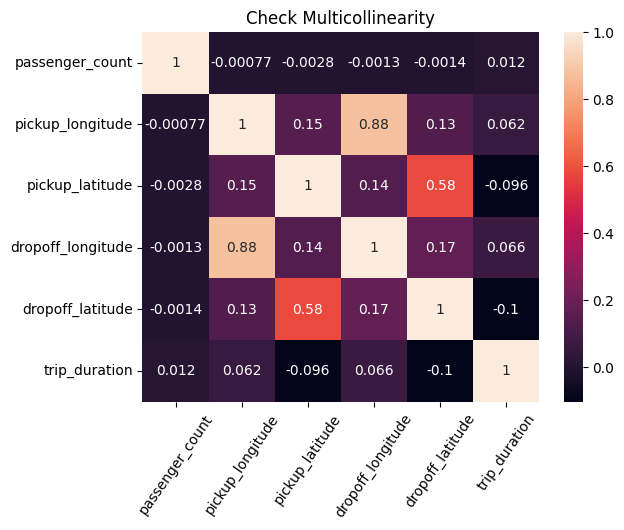

In [48]:
plt.title("Check Multicollinearity")
sns.heatmap(corr_mat, annot=True)
plt.xticks(rotation=55)
plt.show()

I can see that, 
- Pickup Latitude/Longitude are directly porportional to Dropoff Latitude/Longitude

But both have very small collinearity with trip duration

### Data Transformation for ML Training

In [49]:
from sklearn.model_selection import train_test_split

In [50]:
X, y = data.iloc[:, :-1], data.iloc[:,-1]
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2)

In [51]:
print(X.shape, y.shape)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(1384320, 7) (1384320,)
(1107456, 7) (1107456,)
(276864, 7) (276864,)


- ___Datetime format___

In [53]:
class DateExtractor(BaseEstimator, TransformerMixin):
    """
    Extract month, day, hour, and minute from pickup_datetime
    """
    def fit(self,X,y=None):
        return self

    def transform(self, X):
        pickup_month = X['pickup_datetime'].str.split(" ").str[0].str.split("-").str[1].astype(int)
        pickup_day = X['pickup_datetime'].str.split(" ").str[0].str.split("-").str[2].astype(int)
        pickup_hour = X['pickup_datetime'].str.split(" ").str[1].str.split(":").str[0].astype(int)
        pickup_minute = X['pickup_datetime'].str.split(" ").str[1].str.split(":").str[1].astype(int)

        date_time_df = pd.DataFrame({
            "pickup_month": pickup_month,
            "pickup_day" : pickup_day,
            "pickup_hour": pickup_hour,
            "pickup_minute": pickup_minute,
        })

        X_transformed = pd.concat([X.drop(["pickup_datetime"], axis=1), date_time_df], axis=1)
        return X_transformed

    def get_feature_names_out(self, input_features=None):
        return [
            "pickup_month",
            "pickup_day",
            "pickup_hour",
            "pickup_minute",
        ]

- ___Coordinates to Distance___   
The latitude, longitude coordinates are - Radial Coordinates   
Latitude → angle north(+)/south(-) of the Equator   
Longitude → angle east(+)/west(-) of the Prime Meridian    
Ex: Delhi: (28.6, 77.2) → 28.6° N, 77.2° E  


_We will convert coordinates into radian then convert that into distance_

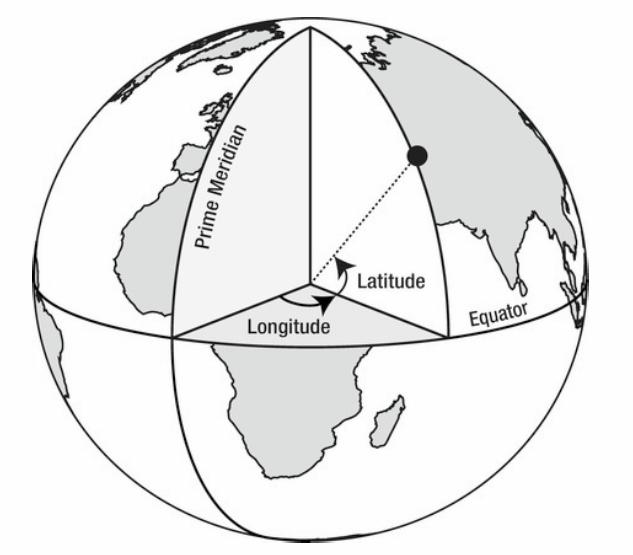

In [55]:
class CoordinatesToDistance(BaseEstimator, TransformerMixin):
    """
    Get distance_km from coordinates
    """
    def fit(self,X,y=None):
        return self

    def transform(self, X):
        distance_km = X.apply(
        lambda row: geodesic(
            (row["pickup_latitude"], row["pickup_longitude"]),
            (row["dropoff_latitude"], row["dropoff_longitude"])
        ).km,
        axis=1
        )

        X_transformed = pd.concat([X, distance_km], axis=1)   
        return X_transformed

    def get_feature_names_out(self, input_features=None):
        return [
            'pickup_latitude',
            'pickup_longitude',
            'dropoff_latitude',
            'dropoff_longitude',
            'distance_km'
        ]

In [56]:
transformer = ColumnTransformer(
    [
        ('DateExtractor', DateExtractor(), ['pickup_datetime']),
        ('Distance_calculator', CoordinatesToDistance(), ['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude'])
    ]
)

In [57]:
X_transformed = transformer.fit_transform(X_train)

In [58]:
X_transformed_df = pd.DataFrame(X_transformed, columns = transformer.get_feature_names_out())
print(X_transformed_df.shape)
X_transformed_df.head()

(1107456, 9)


,DateExtractor__pickup_month,DateExtractor__pickup_day,DateExtractor__pickup_hour,DateExtractor__pickup_minute,Distance_calculator__pickup_latitude,Distance_calculator__pickup_longitude,Distance_calculator__dropoff_latitude,Distance_calculator__dropoff_longitude,Distance_calculator__distance_km
0,5.0,18.0,19.0,46.0,40.743996,-73.985901,40.736938,-73.984596,0.791402
1,4.0,14.0,20.0,11.0,40.795280,-73.971176,40.806602,-73.964867,1.365405
2,6.0,12.0,18.0,25.0,40.760689,-73.969681,40.762611,-73.986931,1.472117
3,2.0,2.0,7.0,26.0,40.743881,-73.979362,40.750652,-73.974403,0.860699
4,6.0,18.0,4.0,20.0,40.716167,-73.963966,40.715542,-73.933899,2.541512


In [59]:
data_transformed = pd.concat([X_transformed_df, y_train.reset_index(drop=True)], axis=1)
print(data_transformed.shape)
data_transformed.head()

(1107456, 10)


,DateExtractor__pickup_month,DateExtractor__pickup_day,DateExtractor__pickup_hour,DateExtractor__pickup_minute,Distance_calculator__pickup_latitude,Distance_calculator__pickup_longitude,Distance_calculator__dropoff_latitude,Distance_calculator__dropoff_longitude,Distance_calculator__distance_km,trip_duration
0,5.0,18.0,19.0,46.0,40.743996,-73.985901,40.736938,-73.984596,0.791402,540
1,4.0,14.0,20.0,11.0,40.795280,-73.971176,40.806602,-73.964867,1.365405,233
2,6.0,12.0,18.0,25.0,40.760689,-73.969681,40.762611,-73.986931,1.472117,774
3,2.0,2.0,7.0,26.0,40.743881,-73.979362,40.750652,-73.974403,0.860699,95
4,6.0,18.0,4.0,20.0,40.716167,-73.963966,40.715542,-73.933899,2.541512,539


### Analysis Of Transformed Data
- We can see that now there is a better correlation between a few feature and target label

In [60]:
data_transformed.corr()['trip_duration'].sort_values(ascending=False)

trip_duration                             1.000000
Distance_calculator__distance_km          0.591714
Distance_calculator__dropoff_longitude    0.061175
Distance_calculator__pickup_longitude     0.057611
DateExtractor__pickup_month               0.038571
DateExtractor__pickup_hour                0.028516
DateExtractor__pickup_day                 0.009514
DateExtractor__pickup_minute             -0.010006
Distance_calculator__pickup_latitude     -0.094720
Distance_calculator__dropoff_latitude    -0.102489
Name: trip_duration, dtype: float64

In [61]:
data.drop(columns=['vendor_id', 'pickup_datetime']).corr()['trip_duration'].sort_values(ascending=False)

trip_duration        1.000000
dropoff_longitude    0.066407
pickup_longitude     0.062260
passenger_count      0.011888
pickup_latitude     -0.095913
dropoff_latitude    -0.103290
Name: trip_duration, dtype: float64

_Clearly, distance is highly correlated with trip duration_

### Data Transformation - Encoding

In [62]:
data.columns

Index(['vendor_id', 'pickup_datetime', 'passenger_count', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'trip_duration'],
      dtype='str')

In [66]:
pipeline = ColumnTransformer(
    [
        ('DateExtractor', DateExtractor(), ['pickup_datetime']),
        ('Distance_calculator', CoordinatesToDistance(), ['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude']),
        ('encoder', OneHotEncoder(), ['vendor_id'])
    ],
    remainder='passthrough'
)

In [67]:
X_transformed_final = pipeline.fit_transform(X_train,y_train)

In [68]:
print(pipeline.get_feature_names_out())
X_transformed_final

['DateExtractor__pickup_month' 'DateExtractor__pickup_day'
 'DateExtractor__pickup_hour' 'DateExtractor__pickup_minute'
 'Distance_calculator__pickup_latitude'
 'Distance_calculator__pickup_longitude'
 'Distance_calculator__dropoff_latitude'
 'Distance_calculator__dropoff_longitude'
 'Distance_calculator__distance_km' 'encoder__vendor_id_1'
 'encoder__vendor_id_2' 'remainder__passenger_count']


array([[ 5., 18., 19., ...,  1.,  0.,  1.],
       [ 4., 14., 20., ...,  1.,  0.,  1.],
       [ 6., 12., 18., ...,  0.,  1.,  1.],
       ...,
       [ 3.,  3., 22., ...,  0.,  1.,  2.],
       [ 4., 29., 15., ...,  1.,  0.,  3.],
       [ 2., 21.,  9., ...,  0.,  1.,  4.]], shape=(1107456, 12))

### Start Training

In [ ]:
callback = EarlyStopping(
    monitor='val_loss',
    min_delta=10000,
    patience=10,
    mode='auto',
    restore_best_weights=True
)

In [ ]:
model = Sequential()

model.add(Input(shape=(X_transformed_final.shape[1],)))
model.add(Dense(64, activation='relu',kernel_regularizer=l1_l2(0.05)))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(Dense(32, activation='relu',kernel_regularizer=l1_l2(0.05)))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(Dense(16, activation='relu',kernel_regularizer=l1_l2(0.05)))
model.add(Dropout(0.1))
model.add(BatchNormalization())
model.add(Dense(1, activation='linear',kernel_regularizer=l1_l2(0.05)))

In [ ]:
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.25 KB)

 Trainable params: 3,681 (14.38 KB)

 Non-trainable params: 224 (896.00 B)

In [ ]:
rmsprop = RMSprop(0.0001)
model.compile(optimizer=rmsprop,metrics=[R2Score(), 'mae'], loss='mean_squared_error')

In [ ]:
history = model.fit(X_transformed_final, y_train, batch_size=2048, epochs=300, verbose=True, callbacks=callback, validation_split=0.2)

Epoch 1/300
433/433 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 734693.4375 - mae: 730.9316 - r2_score: -2.6605 - val_loss: 732331.5625 - val_mae: 729.8448 - val_r2_score: -2.6561
Epoch 2/300
433/433 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 732790.3125 - mae: 730.5667 - r2_score: -2.6511 - val_loss: 728316.7500 - val_mae: 728.3856 - val_r2_score: -2.6361
Epoch 3/300
433/433 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 730517.0000 - mae: 730.1410 - r2_score: -2.6397 - val_loss: 727744.3125 - val_mae: 729.2165 - val_r2_score: -2.6332
Epoch 4/300
433/433 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 728590.3125 - mae: 729.6545 - r2_score: -2.6301 - val_loss: 727143.7500 - val_mae: 729.3477 - val_r2_score: -2.6302
Epoch 5/300
433/433 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 726872.1250 - mae: 729.1089 - r2_score: -2.6216 - val_loss: 724917.1250 - val_mae: 728.2380 - val_r2_score: -2.6191
Epoch 6/300
433/433 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 725130.1250 - mae: 728.5027 - r2_score: -2.6129 -

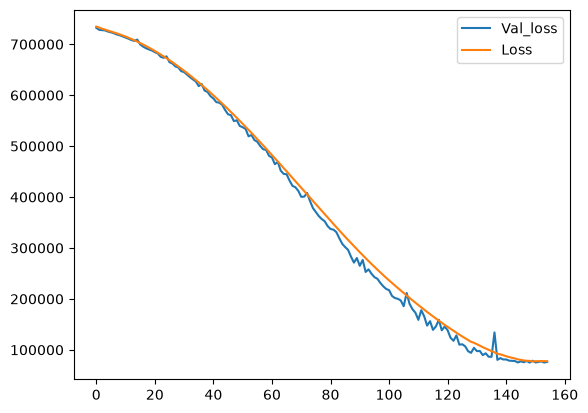

In [ ]:
plt.plot(history.history['val_loss'], label='Val_loss')
plt.plot(history.history['loss'], label= "Loss")
plt.legend()

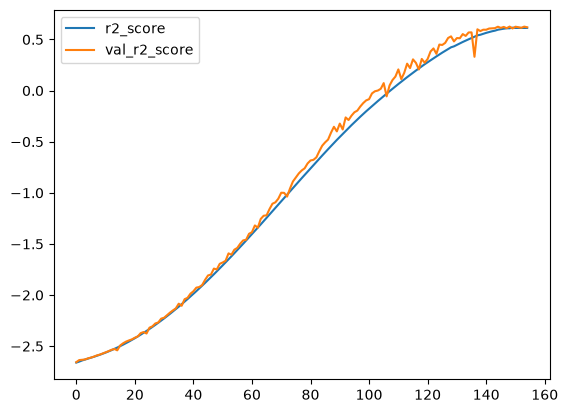

In [ ]:
plt.plot(history.history['r2_score'], label='r2_score')
plt.plot(history.history['val_r2_score'], label='val_r2_score')
plt.legend()

- Dump model

In [ ]:
model.save("model/ann_model.keras")

### Test 

In [69]:
print(X_test.shape, y_test.shape)

(276864, 7) (276864,)


In [70]:
X_test_transformed = pipeline.transform(X_test)

In [71]:
import keras
model = keras.models.load_model("model/ann_model.keras")

In [72]:
predictions = model.predict(X_test_transformed)

8652/8652 ━━━━━━━━━━━━━━━━━━━━ 8s 794us/step


In [73]:
for idx, prediction in enumerate(predictions):
    if prediction<0:
        predictions[idx] = -prediction

In [74]:
rmse = root_mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
rmsle = root_mean_squared_log_error(y_test, predictions)

In [75]:
print("RMSE: ", rmse)
print("RMSLE: ", rmsle)
print("R2 Score: ", r2)

RMSE:  273.2198181152344
RMSLE:  0.46380752325057983
R2 Score:  0.6276479959487915
